In [ ]:

pip install pandas pyxlsb

In [ ]:
import numpy as np
import seaborn as sns
import pandas as pd
import matplotlib.pyplot as plt

In [ ]:
from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
data_path = '/content/drive/Shared drives/EARL/Students/Kaitlyn/Excel Files and Code'

[55.87 47.6  61.9  ...   nan   nan   nan]
[47. 40. 52. ... nan nan nan]
[55.87 47.6  61.9  ...  0.    0.    0.  ]
[47. 40. 52. ...  0.  0.  0.]
[   0    1    2 ... 1497 1498 1499]


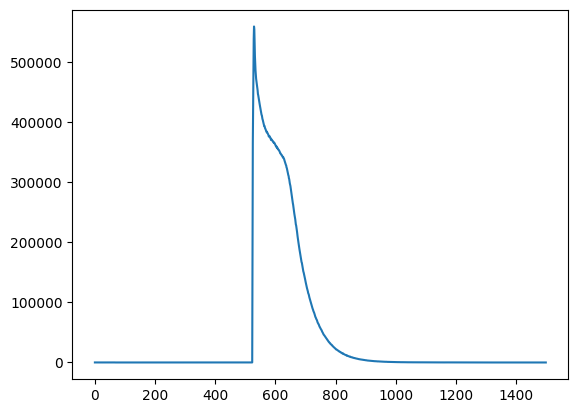

In [ ]:
file_path= '/content/drive/Shared drives/EARL/Students/Kaitlyn/Excel Files and Code/control_061924_org.csv'

# Use pandas to read the CSV, which handles mixed data types better
data_control = pd.read_csv(file_path)

# Access the columns you need
# time = data_control.iloc[:, 0]  #
conc = data_control.iloc[:, 1]  # Second column as concentration
counts = data_control.iloc[:, 2]  # Third column as counts

# If you need 'conc' and 'counts' as NumPy arrays:
conc = conc.to_numpy()
counts = counts.to_numpy()


print(conc)
print(counts)


conc_arr_control = np.nan_to_num(conc, nan=0)
counts_arr_control = np.nan_to_num(counts, nan=0)


print(conc_arr_control)
print(counts_arr_control)


time = np.arange(0, len(conc_arr_control), 1)
print(time)



plt.plot(time, conc_arr_control)


dconc_dt = np.gradient(conc_arr_control, time)

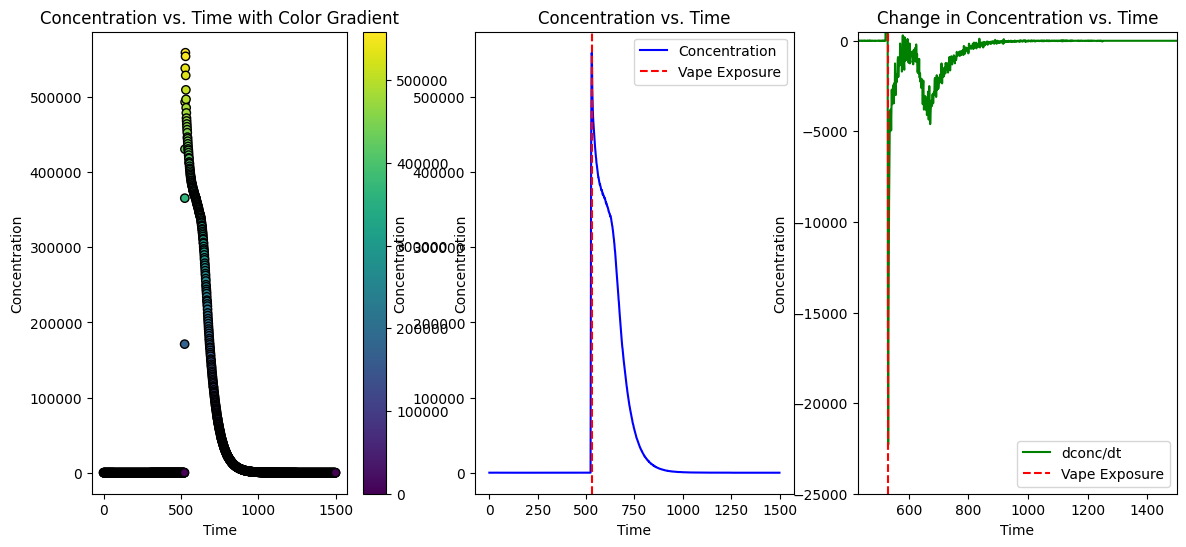

In [ ]:

max_index = np.argmax(conc_arr_control)
max_time = time[max_index]

# Create a figure with two subplots
fig, axs = plt.subplots(1, 3, figsize=(14, 6))

# Scatter plot with color gradient
scatter = axs[0].scatter(time, conc_arr_control, c=conc_arr_control, cmap='viridis', edgecolor='k')
axs[0].set_title('Concentration vs. Time with Color Gradient')
axs[0].set_xlabel('Time')
axs[0].set_ylabel('Concentration')
fig.colorbar(scatter, ax=axs[0], label='Concentration')


# Line plot of concentration over time
axs[1].plot(time, conc_arr_control, label='Concentration', color='blue')
axs[1].set_title('Concentration vs. Time')
axs[1].set_xlabel('Time')
axs[1].set_ylabel('Concentration')
axs[1].axvline(max_time, color='red', linestyle='--', label='Vape Exposure')
axs[1].legend()



#Line plot of change in concentration over time
axs[2].plot(time, dconc_dt, label='dconc/dt', color='green')
axs[2].set_title('Change in Concentration vs. Time')
axs[2].set_xlabel('Time')
axs[2].set_ylabel('Concentration')
axs[2].axvline(max_time, color='red', linestyle='--', label='Vape Exposure')
axs[2].set_xlim(max_time-100, len(conc_arr_control))
axs[2].set_ylim(-25000, 500)
axs[2].legend()

Analyze different Data sets

Create function

In [ ]:
import re
from datetime import datetime

def is_valid_time(time_string):
    try:
        # Attempt to parse the string as a time with the format HH:MM:SS
        datetime.strptime(time_string, "%H:%M:%S")
        return True
    except ValueError:
        # If parsing fails, the format is invalid
        return False

def check_values(array):
  for item in array:
    # Check if any value is NaN or empty
    if pd.isna(item) or str(item).strip() == '':
      return False
  return True

def extract_data(file_path):
  df = pd.read_excel(file_path, header=0)

  values = []

  for i, c in enumerate(df.columns):
    for j, value in enumerate(df[c]):
      if is_valid_time(str(value)):
        try:
          time = df.at[j, df.columns[i]]
          concentration = df.at[j, df.columns[i + 1]]
          count = df.at[j, df.columns[i + 2]]

          if (check_values([time, concentration, count])):
            values.append([time, concentration, count])
        except:
          continue

  return values

Assign data sets

In [ ]:
"Data for : "

data1 = extract_data('/content/drive/Shared drives/EARL/Students/Kaitlyn/Excel Files and Code/12__FIREWORKS_II_Explosion_Sample_2.xls.xlsx')
print(len(data1))
concentration1 = []

for i in range(len(data1)):
   concentration1.append(data1[i][1])

print(concentration1)
print(len(concentration1))

time1 = np.arange(0, len(concentration1), 1)
print(time1)

dconc_dt_1 = np.gradient(concentration1, time1)

NameError: name 'extract_data' is not defined

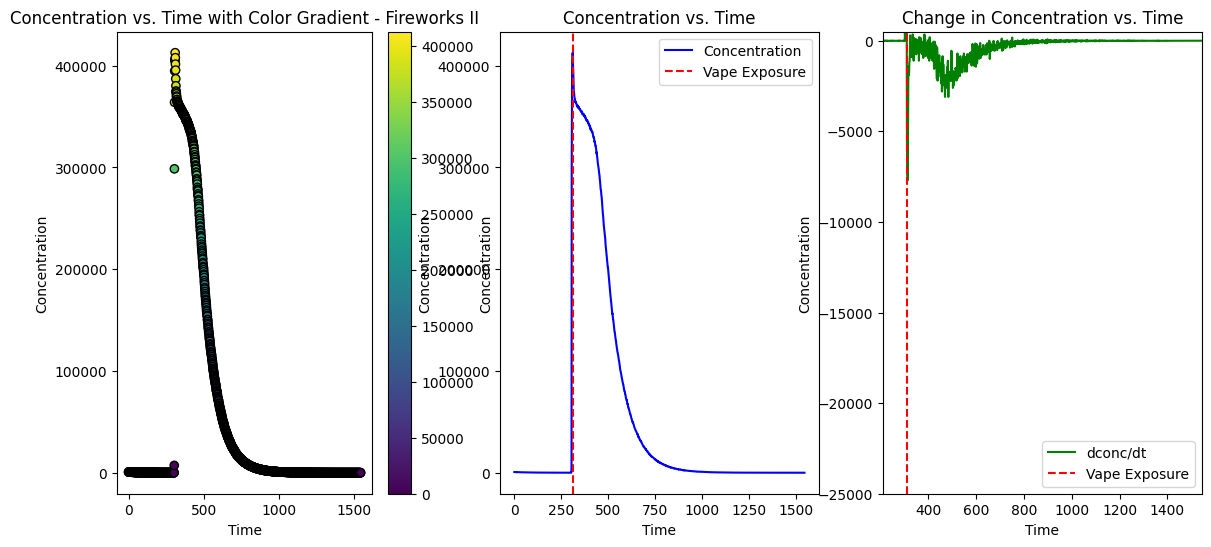

In [ ]:

max_index_1 = np.argmax(concentration1)
max_time_1 = time1[max_index_1]

# Create a figure with two subplots
fig, axs = plt.subplots(1, 3, figsize=(14, 6))

# Scatter plot with color gradient
scatter = axs[0].scatter(time1, concentration1, c=concentration1, cmap='viridis', edgecolor='k')
axs[0].set_title('Concentration vs. Time with Color Gradient - Fireworks II')
axs[0].set_xlabel('Time')
axs[0].set_ylabel('Concentration')
fig.colorbar(scatter, ax=axs[0], label='Concentration')


# Line plot of concentration over time
axs[1].plot(time1, concentration1, label='Concentration', color='blue')
axs[1].set_title('Concentration vs. Time')
axs[1].set_xlabel('Time')
axs[1].set_ylabel('Concentration')
axs[1].axvline(max_time_1, color='red', linestyle='--', label='Vape Exposure')
axs[1].legend()



#Line plot of change in concentration over time
axs[2].plot(time1, dconc_dt_1, label='dconc/dt', color='green')
axs[2].set_title('Change in Concentration vs. Time')
axs[2].set_xlabel('Time')
axs[2].set_ylabel('Concentration')
axs[2].axvline(max_time_1, color='red', linestyle='--', label='Vape Exposure')
axs[2].set_xlim(max_time_1-100, len(concentration1))
axs[2].set_ylim(-25000, 500)
axs[2].legend()

In [ ]:
"Data for : "


data2 = extract_data('/content/drive/Shared drives/EARL/Students/Kaitlyn/Excel Files and Code/CLAREVIEW_EASTGLEN_2_062022.xls.xlsx')
print(len(data2))
concentration2 = []

for i in range(len(data2)):
   concentration2.append(data2[i][1])

print(concentration2)
print(len(concentration2))

time2 = np.arange(0, len(concentration2), 1)
print(time2)

dconc_dt_2 = np.gradient(concentration2, time2)

951
[9.37, 7.02, 7.02, 5.85, 14.07, 8.2, 1.17, 5.85, 8.19, 9.36, 9.37, 5.86, 5.85, 5.85, 5.85, 9.37, 11.71, 14.05, 7.02, 12.89, 9.37, 9.44, 12.97, 7.08, 7.08, 10.62, 8.26, 7.08, 7.08, 4.71, 14.13, 10.61, 9.42, 8.26, 9.44, 10.62, 8.25, 3.54, 3.54, 8.26, 8.26, 5.9, 5.9, 8.25, 9.43, 3.54, 14.14, 10.61, 9.44, 9.44, 12.98, 10.61, 9.43, 5.9, 12.97, 14.15, 7.08, 7.07, 5.89, 7.07, 9.42, 5.89, 7.07, 12.94, 8.24, 11.78, 14.14, 3.54, 11.78, 7.07, 9.44, 8.25, 8.24, 11.77, 7.07, 11.78, 3.54, 5.89, 3.54, 7.07, 4.72, 4.71, 3.54, 8.25, 3.54, 2.36, 7.08, 11.77, 5.9, 9.42, 5.89, 3.54, 3.54, 5.89, 11.78, 5.9, 14.15, 11.79, 5.89, 4.72, 9.43, 10.59, 10.59, 4.72, 9.44, 9.44, 2.36, 3.54, 10.62, 14.15, 4.72, 9.43, 3.54, 9.41, 8.24, 7.07, 3.53, 9.42, 8.25, 8.24, 5.88, 4.68, 3.54, 3.54, 2.36, 4.71, 7.06, 3.53, 3.53, 14.13, 9.42, 10.6, 7.06, 8.24, 5.89, 7.06, 2.36, 11.78, 3.53, 5.89, 3.54, 9.42, 2.36, 9.41, 2.36, 3.53, 7.07, 4.72, 5.89, 2.36, 4.72, 4.72, 4.72, 4.72, 0, 4.72, 4.72, 4.71, 1.18, 5.89, 3.54, 3.54, 8

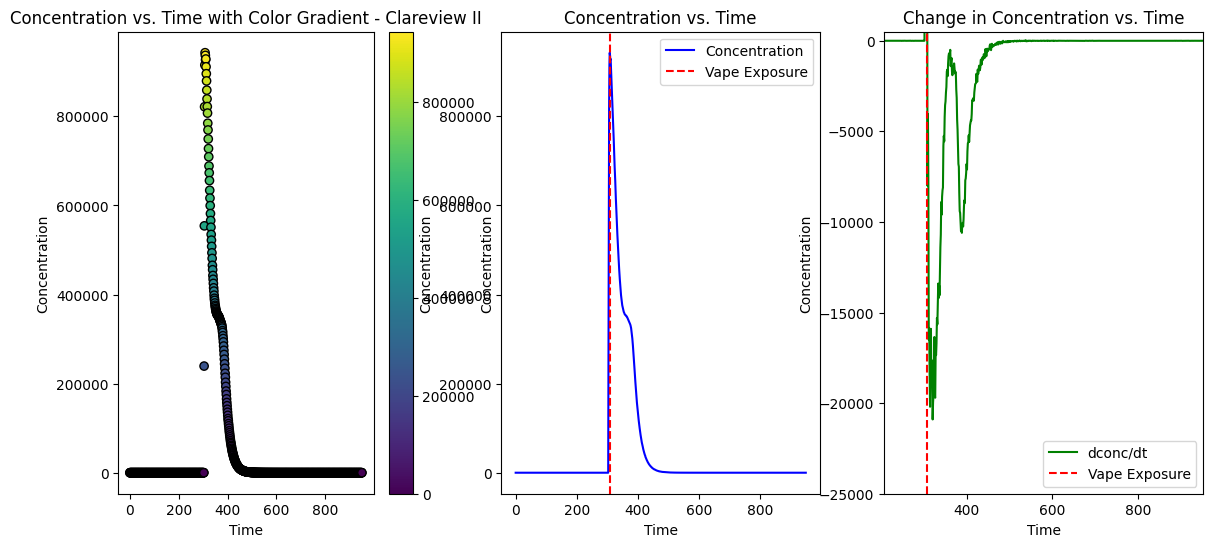

In [ ]:

max_index_2 = np.argmax(concentration2)
max_time_2 = time2[max_index_2]

# Create a figure with two subplots
fig, axs = plt.subplots(1, 3, figsize=(14, 6))

# Scatter plot with color gradient
scatter = axs[0].scatter(time2, concentration2, c=concentration2, cmap='viridis', edgecolor='k')
axs[0].set_title('Concentration vs. Time with Color Gradient - Clareview II')
axs[0].set_xlabel('Time')
axs[0].set_ylabel('Concentration')
fig.colorbar(scatter, ax=axs[0], label='Concentration')


# Line plot of concentration over time
axs[1].plot(time2, concentration2, label='Concentration', color='blue')
axs[1].set_title('Concentration vs. Time')
axs[1].set_xlabel('Time')
axs[1].set_ylabel('Concentration')
axs[1].axvline(max_time_2, color='red', linestyle='--', label='Vape Exposure')
axs[1].legend()



#Line plot of change in concentration over time
axs[2].plot(time2, dconc_dt_2, label='dconc/dt', color='green')
axs[2].set_title('Change in Concentration vs. Time')
axs[2].set_xlabel('Time')
axs[2].set_ylabel('Concentration')
axs[2].axvline(max_time_2, color='red', linestyle='--', label='Vape Exposure')
axs[2].set_xlim(max_time_2-100, len(concentration2))
axs[2].set_ylim(-25000, 500)
axs[2].legend()

In [ ]:
"Data for : "


data3 = extract_data('/content/drive/Shared drives/EARL/Students/Kaitlyn/Excel Files and Code/12_CLAREVIEW_EASTGLEN_061924.xls.xlsx')
print(len(data3))
concentration3 = []

for i in range(len(data3)):
   concentration3.append(data3[i][1])

print(concentration3)
print(len(concentration3))

time3 = np.arange(0, len(concentration3), 1)
print(time3)

dconc_dt_3 = np.gradient(concentration3, time3)

1626
[51.56, 59.7, 63.09, 57.29, 73.67, 59.48, 58.39, 47.87, 71.21, 54.88, 66.59, 70.12, 56.1, 60.77, 53.73, 63.05, 70.06, 59.57, 61.88, 45.44, 59.52, 67.69, 58.39, 66.51, 58.4, 71.23, 56.04, 73.57, 64.22, 59.54, 58.38, 57.21, 50.22, 61.9, 61.88, 60.73, 46.8, 62.01, 47.97, 71.3, 52.65, 73.68, 52.65, 57.3, 53.79, 58.37, 54.91, 59.52, 52.54, 73.52, 81.75, 61.89, 51.39, 69.03, 60.81, 40.95, 58.5, 57.36, 59.63, 74.91, 61.9, 53.68, 63.15, 73.75, 51.52, 55.03, 50.34, 73.77, 66.74, 58.29, 43.2, 68.85, 64.14, 68.83, 71.18, 65.39, 52.6, 54.96, 43.3, 72.56, 66.65, 58.53, 53.91, 72.79, 46.88, 66.53, 68.67, 78.18, 54.86, 65.4, 52.26, 59.12, 64.92, 61.56, 56.87, 63.88, 58.14, 54.64, 47.83, 46.88, 52.81, 61.06, 73.97, 57.26, 49.54, 60.14, 63.79, 57.82, 54.35, 68.49, 31.79, 43.28, 52.48, 51.24, 52.54, 50.7, 65.94, 62.7, 67.43, 61.53, 56.86, 66.01, 45.5, 62.82, 45.47, 56.01, 53.68, 54.85, 54.97, 51.51, 63.23, 62.02, 76.55, 76.55, 63.63, 42.46, 50.74, 69.62, 56.6, 53.91, 46.87, 46.81, 64.41, 36.35, 45.

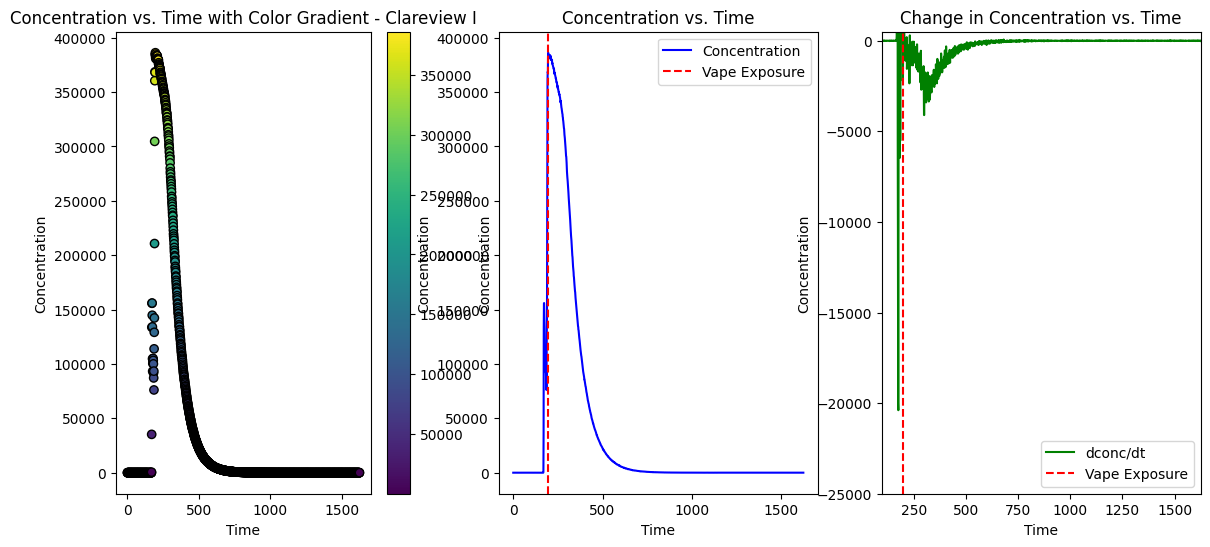

In [ ]:

max_index_3 = np.argmax(concentration3)
max_time_3 = time3[max_index_3]

# Create a figure with two subplots
fig, axs = plt.subplots(1, 3, figsize=(14, 6))

# Scatter plot with color gradient
scatter = axs[0].scatter(time3, concentration3, c=concentration3, cmap='viridis', edgecolor='k')
axs[0].set_title('Concentration vs. Time with Color Gradient - Clareview I')
axs[0].set_xlabel('Time')
axs[0].set_ylabel('Concentration')
fig.colorbar(scatter, ax=axs[0], label='Concentration')


# Line plot of concentration over time
axs[1].plot(time3, concentration3, label='Concentration', color='blue')
axs[1].set_title('Concentration vs. Time')
axs[1].set_xlabel('Time')
axs[1].set_ylabel('Concentration')
axs[1].axvline(max_time_3, color='red', linestyle='--', label='Vape Exposure')
axs[1].legend()



#Line plot of change in concentration over time
axs[2].plot(time3, dconc_dt_3, label='dconc/dt', color='green')
axs[2].set_title('Change in Concentration vs. Time')
axs[2].set_xlabel('Time')
axs[2].set_ylabel('Concentration')
axs[2].axvline(max_time_3, color='red', linestyle='--', label='Vape Exposure')
axs[2].set_xlim(max_time_3-100, len(concentration3))
axs[2].set_ylim(-25000, 500)
axs[2].legend()

In [ ]:
"Data for : "


data4 = extract_data('/content/drive/Shared drives/EARL/Students/Kaitlyn/Excel Files and Code/12__VIKING_CHINA_BERRY_Sample_2_07232024.xls.xlsx')
print(len(data4))
concentration4 = []

for i in range(len(data4)):
   concentration4.append(data4[i][1])

print(concentration4)
print(len(concentration4))

time4 = np.arange(0, len(concentration4), 1)
print(time4)

dconc_dt_4 = np.gradient(concentration4, time4)

938
[33.92, 24.61, 28.14, 30.57, 20.01, 36.5, 24.74, 29.6, 23.52, 29.4, 21.15, 16.47, 16.57, 17.76, 18.91, 18.89, 20.16, 15.44, 13.06, 9.52, 20.12, 10.66, 8.34, 15.47, 11.92, 15.36, 14.16, 15.34, 8.27, 9.4, 5.85, 5.83, 8.19, 8.19, 12.88, 4.69, 4.7, 7.05, 5.86, 4.68, 7.05, 7.13, 4.72, 5.91, 3.57, 5.95, 2.38, 1.19, 2.38, 3.57, 8.33, 3.54, 3.55, 2.38, 5.9, 2.36, 1.18, 2.34, 0, 2.38, 2.38, 2.36, 90511, 705700, 875100, 1000000, 988400, 960700, 910400, 821200, 956300, 1000000, 1000000, 1000000, 1000000, 1000000, 1000000, 1000000, 1000000, 1000000, 1000000, 1000000, 1000000, 1000000, 1000000, 1000000, 1000000, 1000000, 1000000, 1000000, 1000000, 994500, 998600, 975900, 956900, 954100, 929900, 908000, 891500, 867300, 837000, 816700, 808700, 793200, 776100, 764600, 741100, 722900, 696100, 684400, 667100, 656100, 636300, 628200, 613700, 596200, 588600, 574400, 568800, 562700, 538700, 530300, 510700, 501900, 490000, 479000, 468600, 456900, 446200, 443900, 441900, 441400, 428900, 420900, 417700, 4

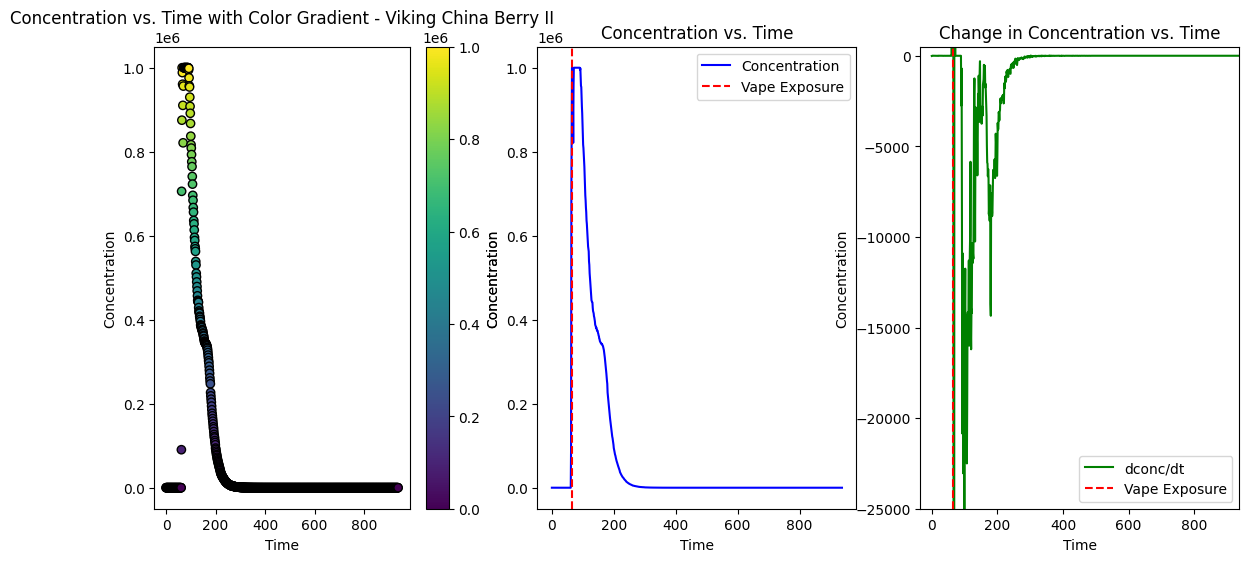

In [ ]:

max_index_4 = np.argmax(concentration4)
max_time_4 = time4[max_index_4]

# Create a figure with two subplots
fig, axs = plt.subplots(1, 3, figsize=(14, 6))

# Scatter plot with color gradient
scatter = axs[0].scatter(time4, concentration4, c=concentration4, cmap='viridis', edgecolor='k')
axs[0].set_title('Concentration vs. Time with Color Gradient - Viking China Berry II')
axs[0].set_xlabel('Time')
axs[0].set_ylabel('Concentration')
fig.colorbar(scatter, ax=axs[0], label='Concentration')


# Line plot of concentration over time
axs[1].plot(time4, concentration4, label='Concentration', color='blue')
axs[1].set_title('Concentration vs. Time')
axs[1].set_xlabel('Time')
axs[1].set_ylabel('Concentration')
axs[1].axvline(max_time_4, color='red', linestyle='--', label='Vape Exposure')
axs[1].legend()



#Line plot of change in concentration over time
axs[2].plot(time4, dconc_dt_4, label='dconc/dt', color='green')
axs[2].set_title('Change in Concentration vs. Time')
axs[2].set_xlabel('Time')
axs[2].set_ylabel('Concentration')
axs[2].axvline(max_time_4, color='red', linestyle='--', label='Vape Exposure')
axs[2].set_xlim(max_time_4-100, len(concentration4))
axs[2].set_ylim(-25000, 500)
axs[2].legend()

In [ ]:
"Data for : "


data5 = extract_data('/content/drive/Shared drives/EARL/Students/Kaitlyn/Excel Files and Code/12__VIKING_CHINA_BERRY_Sample_1_07152024.xls.xlsx')
print(len(data5))
concentration5 = []

for i in range(len(data5)):
   concentration5.append(data5[i][1])

print(concentration5)
print(len(concentration5))

time5 = np.arange(0, len(concentration5), 1)
print(time5)

dconc_dt_5 = np.gradient(concentration5, time5)

938
[33.92, 24.61, 28.14, 30.57, 20.01, 36.5, 24.74, 29.6, 23.52, 29.4, 21.15, 16.47, 16.57, 17.76, 18.91, 18.89, 20.16, 15.44, 13.06, 9.52, 20.12, 10.66, 8.34, 15.47, 11.92, 15.36, 14.16, 15.34, 8.27, 9.4, 5.85, 5.83, 8.19, 8.19, 12.88, 4.69, 4.7, 7.05, 5.86, 4.68, 7.05, 7.13, 4.72, 5.91, 3.57, 5.95, 2.38, 1.19, 2.38, 3.57, 8.33, 3.54, 3.55, 2.38, 5.9, 2.36, 1.18, 2.34, 0, 2.38, 2.38, 2.36, 90511, 705700, 875100, 1000000, 988400, 960700, 910400, 821200, 956300, 1000000, 1000000, 1000000, 1000000, 1000000, 1000000, 1000000, 1000000, 1000000, 1000000, 1000000, 1000000, 1000000, 1000000, 1000000, 1000000, 1000000, 1000000, 1000000, 1000000, 994500, 998600, 975900, 956900, 954100, 929900, 908000, 891500, 867300, 837000, 816700, 808700, 793200, 776100, 764600, 741100, 722900, 696100, 684400, 667100, 656100, 636300, 628200, 613700, 596200, 588600, 574400, 568800, 562700, 538700, 530300, 510700, 501900, 490000, 479000, 468600, 456900, 446200, 443900, 441900, 441400, 428900, 420900, 417700, 4

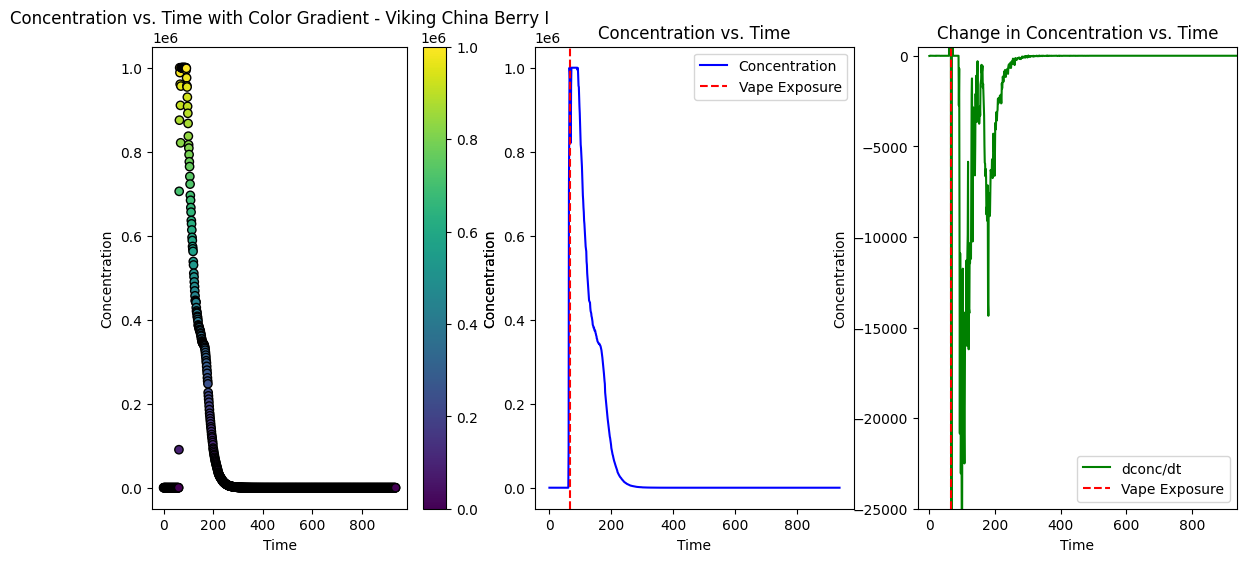

In [ ]:

max_index_5 = np.argmax(concentration5)
max_time_5 = time5[max_index_5]

# Create a figure with two subplots
fig, axs = plt.subplots(1, 3, figsize=(14, 6))

# Scatter plot with color gradient
scatter = axs[0].scatter(time5, concentration5, c=concentration5, cmap='viridis', edgecolor='k')
axs[0].set_title('Concentration vs. Time with Color Gradient - Viking China Berry I')
axs[0].set_xlabel('Time')
axs[0].set_ylabel('Concentration')
fig.colorbar(scatter, ax=axs[0], label='Concentration')


# Line plot of concentration over time
axs[1].plot(time5, concentration5, label='Concentration', color='blue')
axs[1].set_title('Concentration vs. Time')
axs[1].set_xlabel('Time')
axs[1].set_ylabel('Concentration')
axs[1].axvline(max_time_5, color='red', linestyle='--', label='Vape Exposure')
axs[1].legend()



#Line plot of change in concentration over time
axs[2].plot(time5, dconc_dt_5, label='dconc/dt', color='green')
axs[2].set_title('Change in Concentration vs. Time')
axs[2].set_xlabel('Time')
axs[2].set_ylabel('Concentration')
axs[2].axvline(max_time_5, color='red', linestyle='--', label='Vape Exposure')
axs[2].set_xlim(max_time_5-100, len(concentration5))
axs[2].set_ylim(-25000, 500)
axs[2].legend()

In [ ]:
"Data for : "


data5 = extract_data('/content/drive/Shared drives/EARL/Students/Kaitlyn/Excel Files and Code/12__VIKING_CHINA_BERRY_Sample_1_07152024.xls.xlsx')
print(len(data5))
concentration5 = []

for i in range(len(data5)):
   concentration5.append(data5[i][1])

print(concentration5)
print(len(concentration5))

time5 = np.arange(0, len(concentration5), 1)
print(time5)

dconc_dt_5 = np.gradient(concentration5, time5)

NameError: name 'extract_data' is not defined

In [ ]:
import re
from datetime import datetime

def is_valid_time(time_string):
    try:
        # Attempt to parse the string as a time with the format HH:MM:SS
        datetime.strptime(time_string, "%H:%M:%S")
        return True
    except ValueError:
        # If parsing fails, the format is invalid
        return False

def check_values(array):
  for item in array:
    # Check if any value is NaN or empty
    if pd.isna(item) or str(item).strip() == '':
      return False
  return True

def extract_data(file_path):
  df = pd.read_excel(file_path, header=0)

  values = []

  for i, c in enumerate(df.columns):
    for j, value in enumerate(df[c]):
      if is_valid_time(str(value)):
        try:
          time = df.at[j, df.columns[i]]
          concentration = df.at[j, df.columns[i + 1]]
          count = df.at[j, df.columns[i + 2]]

          if (check_values([time, concentration, count])):
            values.append([time, concentration, count])
        except:
          continue

  return values

In [ ]:
"Data for : "


data5 = extract_data('/content/drive/Shared drives/EARL/Students/Kaitlyn/Excel Files and Code/12__VIKING_CHINA_BERRY_Sample_1_07152024.xls.xlsx')
print(len(data5))
concentration5 = []

for i in range(len(data5)):
   concentration5.append(data5[i][1])

print(concentration5)
print(len(concentration5))

time5 = np.arange(0, len(concentration5), 1)
print(time5)

dconc_dt_5 = np.gradient(concentration5, time5)

1098
[4.76, 14.25, 4.76, 8.32, 7.13, 8.27, 8.26, 5.9, 7.08, 9.44, 12.98, 10.64, 9.44, 5.9, 5.9, 5.9, 9.44, 11.8, 7.08, 7.08, 11.8, 11.8, 7.08, 9.45, 18.89, 7.09, 8.26, 7.08, 12.99, 10.65, 7.08, 4.72, 10.62, 10.62, 3.54, 8.26, 7.08, 10.62, 8.26, 4.72, 12.99, 10.64, 5.9, 11.82, 4.72, 9.44, 16.52, 14.16, 15.34, 11.8, 1.18, 7.08, 7.08, 3.54, 4.72, 5.89, 4.71, 1.18, 3.54, 3.54, 2.36, 9.44, 5.9, 3.54, 1.18, 4.72, 4.72, 9.44, 2.36, 7.1, 7.13, 3.57, 3.57, 7.13, 7.1, 5.94, 7.13, 3.56, 4.75, 5.96, 4.8, 4.79, 5.95, 4.76, 8.33, 7.07, 124733, 407100, 584800, 627300, 635800, 624300, 606400, 589400, 566900, 550800, 530800, 512100, 491000, 474700, 5.9, 8.26, 12.97, 11.8, 12.97, 10.6, 14.16, 8.25, 14.13, 12.94, 10.62, 9.43, 25.89, 12.95, 9.4, 14.07, 15.23, 14.06, 12.89, 11.73, 11.71, 4.68, 15.23, 5.86, 9.4, 10.6, 5.9, 7.08, 7.08, 8.27, 4.76, 5.9, 3.57, 3.54, 7.08, 9.44, 3.54, 5.9, 7.08, 3.54, 11.79, 5.9, 10.6, 8.26, 10.62, 11.79, 8.26, 5.9, 10.62, 8.26, 12.98, 5.9, 10.62, 8.26, 7.08, 4.72, 5.91, 10.63,

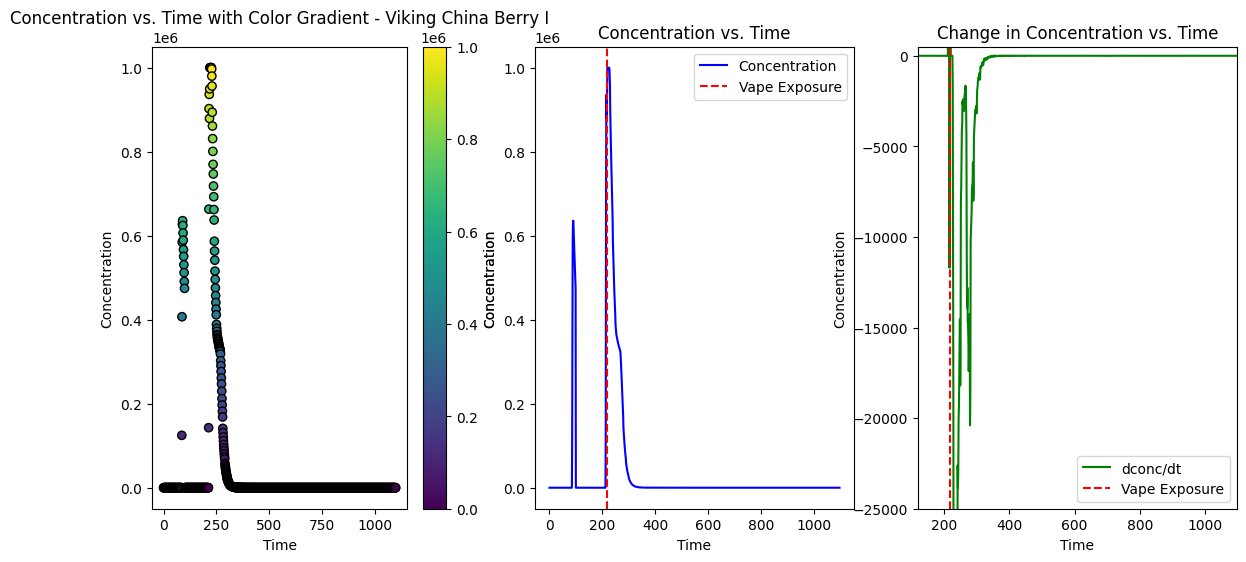

In [ ]:

max_index_5 = np.argmax(concentration5)
max_time_5 = time5[max_index_5]

# Create a figure with two subplots
fig, axs = plt.subplots(1, 3, figsize=(14, 6))

# Scatter plot with color gradient
scatter = axs[0].scatter(time5, concentration5, c=concentration5, cmap='viridis', edgecolor='k')
axs[0].set_title('Concentration vs. Time with Color Gradient - Viking China Berry I')
axs[0].set_xlabel('Time')
axs[0].set_ylabel('Concentration')
fig.colorbar(scatter, ax=axs[0], label='Concentration')


# Line plot of concentration over time
axs[1].plot(time5, concentration5, label='Concentration', color='blue')
axs[1].set_title('Concentration vs. Time')
axs[1].set_xlabel('Time')
axs[1].set_ylabel('Concentration')
axs[1].axvline(max_time_5, color='red', linestyle='--', label='Vape Exposure')
axs[1].legend()



#Line plot of change in concentration over time
axs[2].plot(time5, dconc_dt_5, label='dconc/dt', color='green')
axs[2].set_title('Change in Concentration vs. Time')
axs[2].set_xlabel('Time')
axs[2].set_ylabel('Concentration')
axs[2].axvline(max_time_5, color='red', linestyle='--', label='Vape Exposure')
axs[2].set_xlim(max_time_5-100, len(concentration5))
axs[2].set_ylim(-25000, 500)
axs[2].legend()

In [ ]:
import numpy as np

def residual_and_jacobian(w, param):
    # -------------------------
    # unknowns: w = [D,B,L,V,x1,x2,x3,y1,y2,y3]
    # -------------------------
    D, B, L, V, x1, x2, x3, y1, y2, y3 = w

    # -------------------------
    # params: [F, z, q, r, b, alp]
    # -------------------------
    F, z, q, r, b, alp = param

    # helpers
    def y_eq(x):
        return alp * x / (1.0 + (alp - 1.0) * x)

    def dy_dx(x):
        den = 1.0 + (alp - 1.0) * x
        return alp / (den * den)

    # convenience
    A = (L + q * F)           # (L + qF)
    G = (V + (1.0 - q) * F)   # (V + (1-q)F)

    res = np.zeros(10)
    J   = np.zeros((10, 10))

    # indices: [D,B,L,V,x1,x2,x3,y1,y2,y3]
    iD,iB,iL,iV = 0,1,2,3
    ix1,ix2,ix3 = 4,5,6
    iy1,iy2,iy3 = 7,8,9

    # ------------------------------------------------------------
    # r2 = r*D - L
    # ------------------------------------------------------------
    res[0] = r*D - L
    J[0,iD] = r
    J[0,iL] = -1.0

    # ------------------------------------------------------------
    # r3 = b*B - V
    # ------------------------------------------------------------
    res[1] = b*B - V
    J[1,iB] = b
    J[1,iV] = -1.0

    # ------------------------------------------------------------
    # r4 = D + L - V - (1-q)*F
    # ------------------------------------------------------------
    res[2] = D + L - V - (1.0 - q)*F
    J[2,iD] = 1.0
    J[2,iL] = 1.0
    J[2,iV] = -1.0

    # ------------------------------------------------------------
    # r5 = V + B - L - q*F
    # ------------------------------------------------------------
    res[3] = V + B - L - q*F
    J[3,iV] = 1.0
    J[3,iB] = 1.0
    J[3,iL] = -1.0

    # ------------------------------------------------------------
    # r6 = (L+qF)x2 + Vx1 - (L+qF)x1 - V*y1
    # ------------------------------------------------------------
    res[4] = A*x2 + V*x1 - A*x1 - V*y1

    # d/dL: (x2 - x1) because dA/dL = 1
    J[4,iL]  = (x2 - x1)
    # d/dV: (x1 - y1)
    J[4,iV]  = (x1 - y1)
    # d/dx1: (V - A)
    J[4,ix1] = (V - A)
    # d/dx2: A
    J[4,ix2] = A
    # d/dy1: -V
    J[4,iy1] = -V

    # ------------------------------------------------------------
    # r7 = y1 - y_eq(x1)
    # ------------------------------------------------------------
    res[5] = y1 - y_eq(x1)
    J[5,iy1] = 1.0
    J[5,ix1] = -dy_dx(x1)

    # ------------------------------------------------------------
    # r8 = Lx3 + Fz + V*y1 - (L+qF)x2 - (V+(1-q)F)y2
    # ------------------------------------------------------------
    res[6] = L*x3 + F*z + V*y1 - A*x2 - G*y2

    # d/dL: x3 - x2  (since A depends on L)
    J[6,iL]  = (x3 - x2)
    # d/dV: y1 - y2  (since G depends on V)
    J[6,iV]  = (y1 - y2)
    # d/dx2: -A
    J[6,ix2] = -A
    # d/dx3: L
    J[6,ix3] = L
    # d/dy1: V
    J[6,iy1] = V
    # d/dy2: -G
    J[6,iy2] = -G

    # ------------------------------------------------------------
    # r9 = y2 - y_eq(x2)
    # ------------------------------------------------------------
    res[7] = y2 - y_eq(x2)
    J[7,iy2] = 1.0
    J[7,ix2] = -dy_dx(x2)

    # ------------------------------------------------------------
    # r10 = L*y3 + (V+(1-q)F)*y2 - L*x3 - (V+(1-q)F)*y3
    #     = L*(y3 - x3) + G*(y2 - y3)
    # ------------------------------------------------------------
    res[8] = L*y3 + G*y2 - L*x3 - G*y3

    # d/dL: (y3 - x3)
    J[8,iL]  = (y3 - x3)
    # d/dV: (y2 - y3) because dG/dV = 1
    J[8,iV]  = (y2 - y3)
    # d/dx3: -L
    J[8,ix3] = -L
    # d/dy2: G
    J[8,iy2] = G
    # d/dy3: L - G
    J[8,iy3] = (L - G)


    # ------------------------------------------------------------
    # r11 = y3 - y_eq(x3)
    # ------------------------------------------------------------
    res[9] = y3 - y_eq(x3)
    J[9,iy3] = 1.0
    J[9,ix3] = -dy_dx(x3)

    return res, J